In [ ]:
%pip install -q rasterio pyproj
%pip install -q git+https://github.com/cvg/LightGlue.git

In [ ]:
%pip install git+https://github.com/facebookresearch/co-tracker.git

In [1]:
import matplotlib.pyplot as plt
import rasterio
import cv2
import numpy as np
import os

Розмір карти завантажено: 1367x846 пікселів


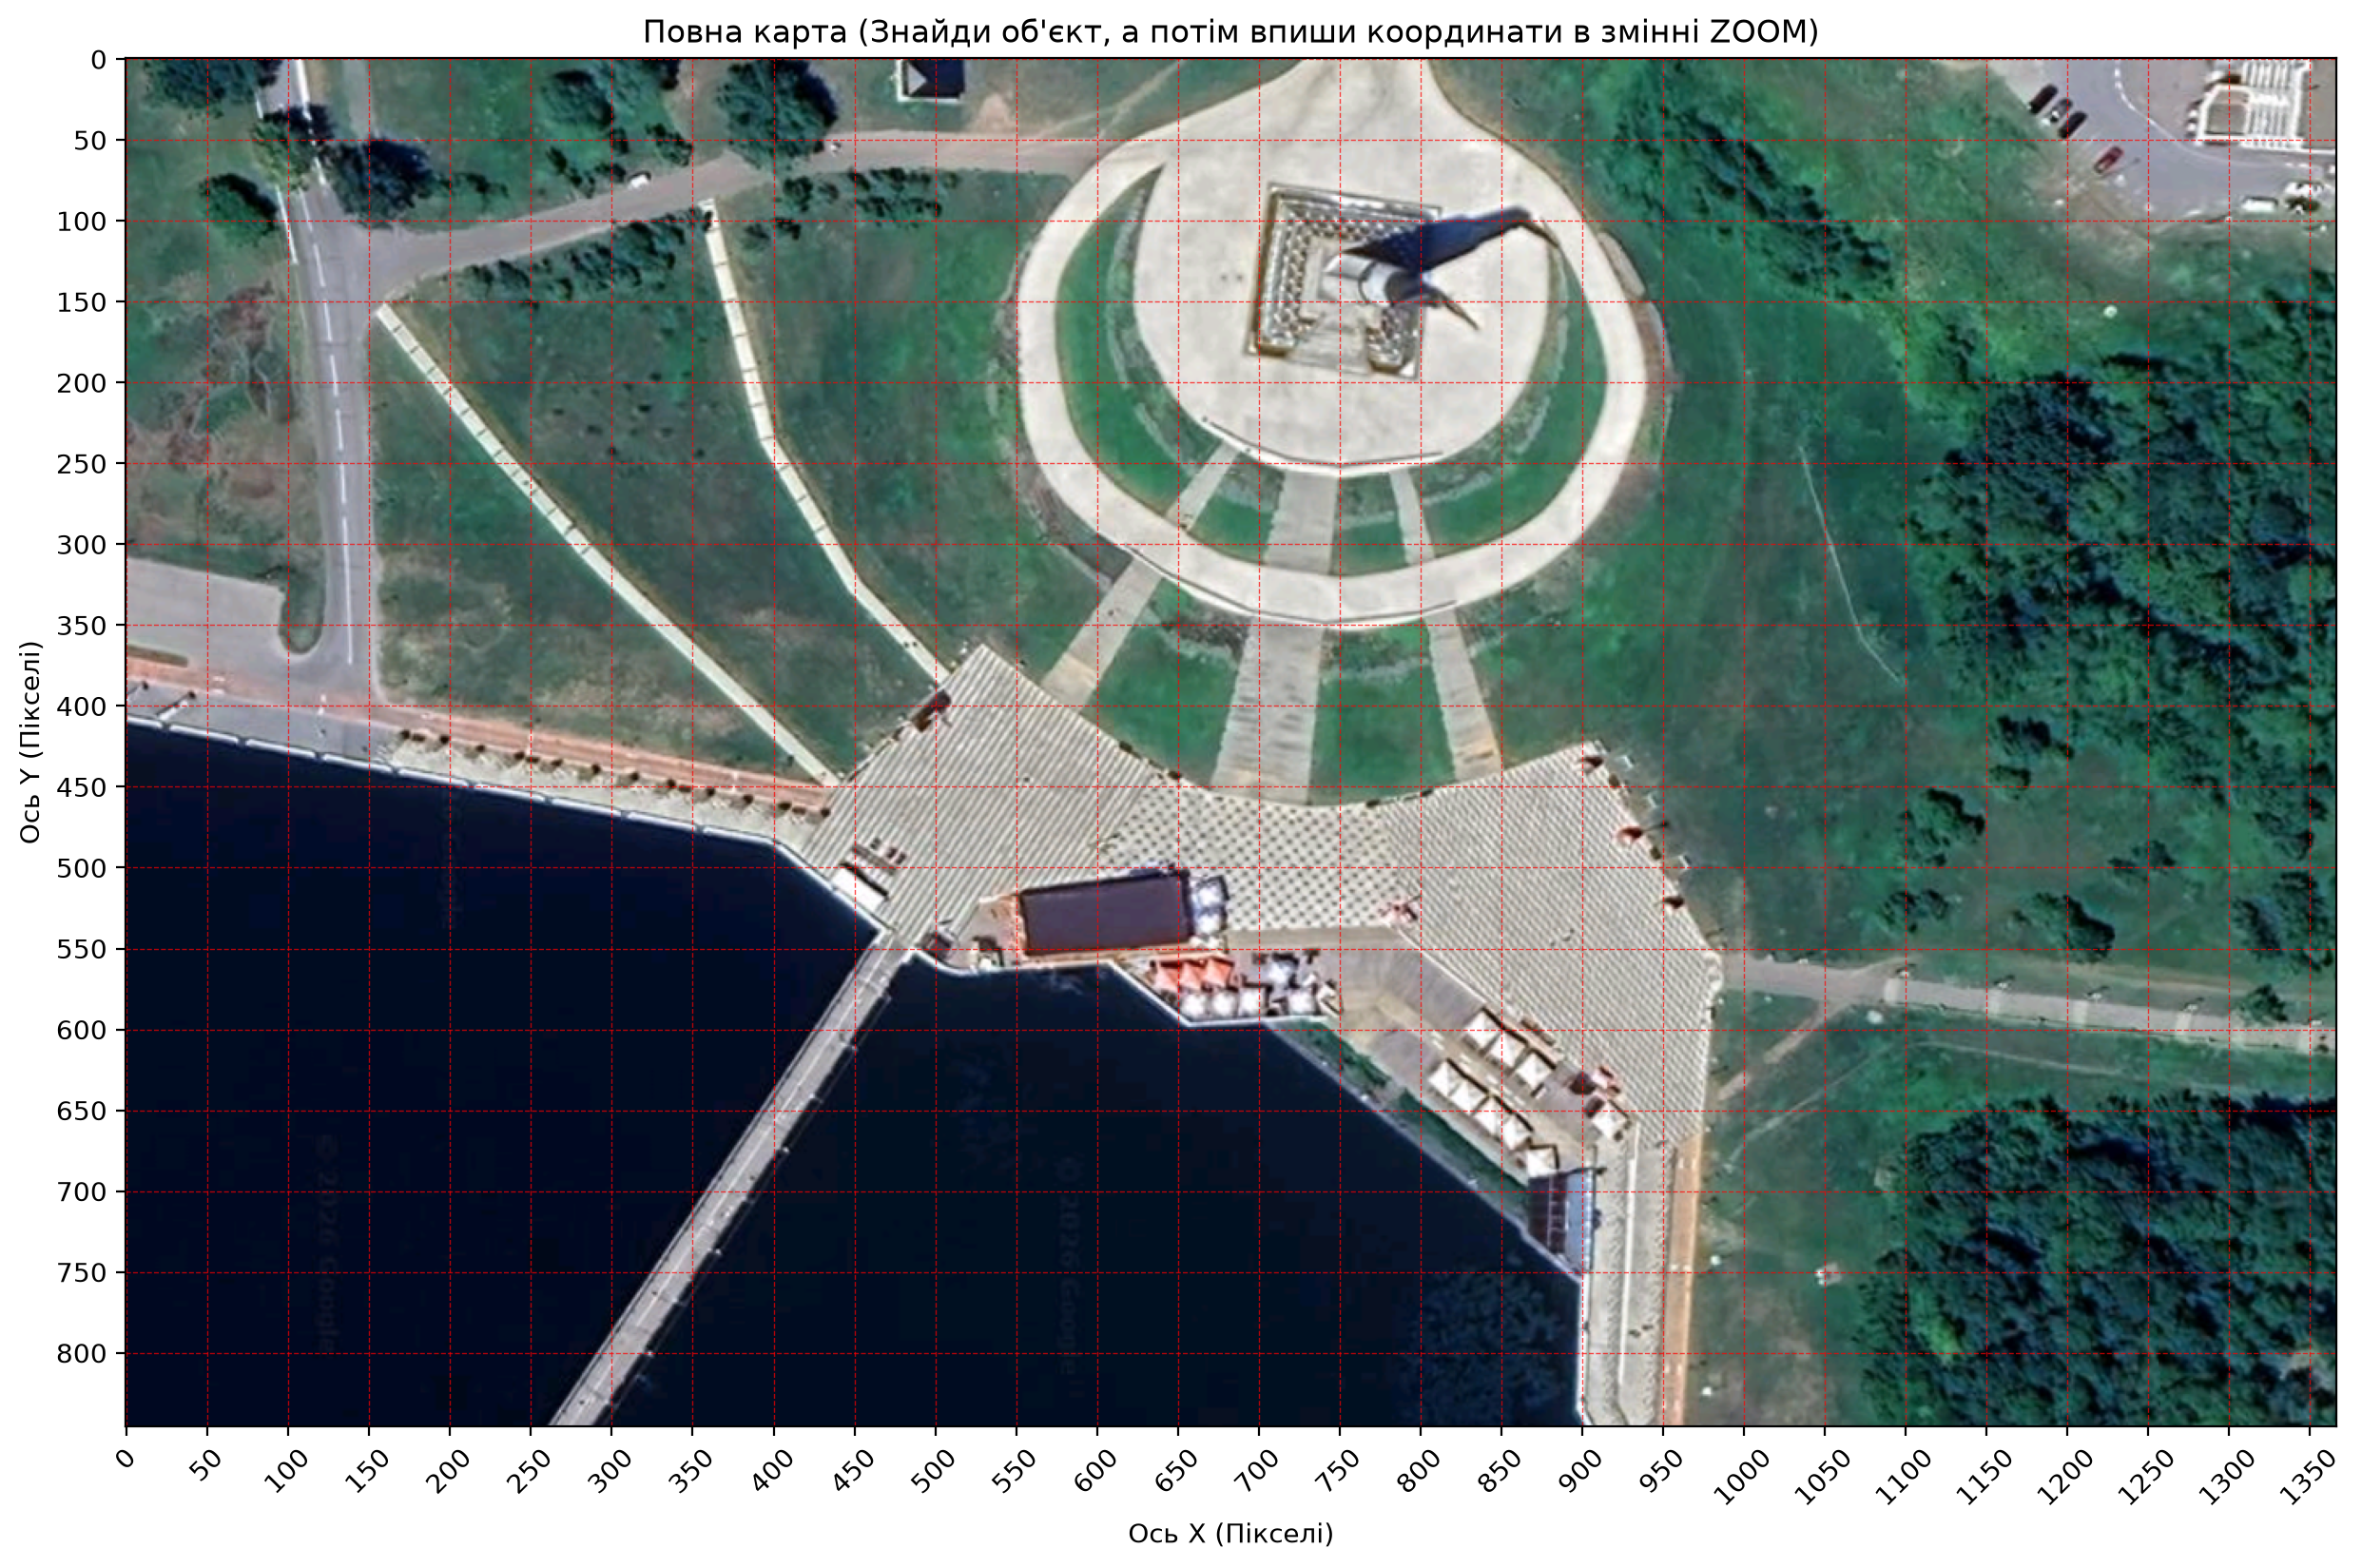

In [2]:
# ==========================================
# ШЛЯХ ДО ФОТО КАРТИ
# ==========================================
map_img_path = 'map8.jpg'  # Заміни на 'map.jpg', якщо це твій власний JPEG файл

# Завантаження залежно від формату файлу
if map_img_path.lower().endswith(('.tif', '.tiff')):
    with rasterio.open(map_img_path) as dataset:
        sat_image = dataset.read()
        sat_image = np.transpose(sat_image, (1, 2, 0))
        if sat_image.shape[2] == 4:
            sat_image = sat_image[:, :, :3]
else:
    # Для звичайних JPEG / PNG фотографій
    sat_image = cv2.imread(map_img_path)
    if sat_image is not None:
        sat_image = cv2.cvtColor(sat_image, cv2.COLOR_BGR2RGB)
    else:
        raise FileNotFoundError(f"Не вдалося знайти файл карти за шляхом: {map_img_path}")

sat_h, sat_w = sat_image.shape[:2]
print(f"Розмір карти завантажено: {sat_w}x{sat_h} пікселів")

# ==========================================
# НАЛАШТУВАННЯ ЗУМУ (ЛУПА)
# 1. Залиш None, щоб побачити всю карту.
# 2. Знайди об'єкт приблизно і впиши сюди межі квадрата, щоб наблизити!
# ==========================================
ZOOM_X_MIN = None  # наприклад, 2500
ZOOM_X_MAX = None  # наприклад, 3000
ZOOM_Y_MIN = None  # наприклад, 5500
ZOOM_Y_MAX = None  # наприклад, 6000

fig, ax = plt.subplots(figsize=(15, 15), dpi=200)

if ZOOM_X_MIN is not None and ZOOM_X_MAX is not None:
    # Вирізаємо потрібний шматок карти
    cropped_image = sat_image[ZOOM_Y_MIN:ZOOM_Y_MAX, ZOOM_X_MIN:ZOOM_X_MAX]

    # extent зберігає правильні оригінальні координати на осях
    ax.imshow(cropped_image, extent=[ZOOM_X_MIN, ZOOM_X_MAX, ZOOM_Y_MAX, ZOOM_Y_MIN])

    # Робимо дуже густу сітку (кожні 10 пікселів) для максимальної точності
    ax.set_xticks(np.arange(ZOOM_X_MIN, ZOOM_X_MAX, 10))
    ax.set_yticks(np.arange(ZOOM_Y_MIN, ZOOM_Y_MAX, 10))
    ax.grid(color='cyan', linestyle='-', linewidth=0.8, alpha=0.9)
    plt.title("Максимальне наближення (Сітка кожні 10 пікселів)")
else:
    # Показуємо всю карту
    ax.imshow(sat_image)
    ax.set_xticks(np.arange(0, sat_w, 50))
    ax.set_yticks(np.arange(0, sat_h, 50))
    ax.grid(color='red', linestyle='--', linewidth=0.5, alpha=0.7)
    plt.title("Повна карта (Знайди об'єкт, а потім впиши координати в змінні ZOOM)")

# Обертаємо підписи на осі X, щоб вони не зливалися при густій сітці
plt.xticks(rotation=45)
plt.xlabel("Ось X (Пікселі)")
plt.ylabel("Ось Y (Пікселі)")
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import torchvision.transforms.functional as TF
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd
from matplotlib.patches import ConnectionPatch
from IPython.display import display
import importlib
from sklearn.model_selection import train_test_split
from lightglue.utils import numpy_image_to_torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
from tqdm import tqdm

1/4:  12%|█▏        | 52/425 [00:16<01:59,  3.13it/s]


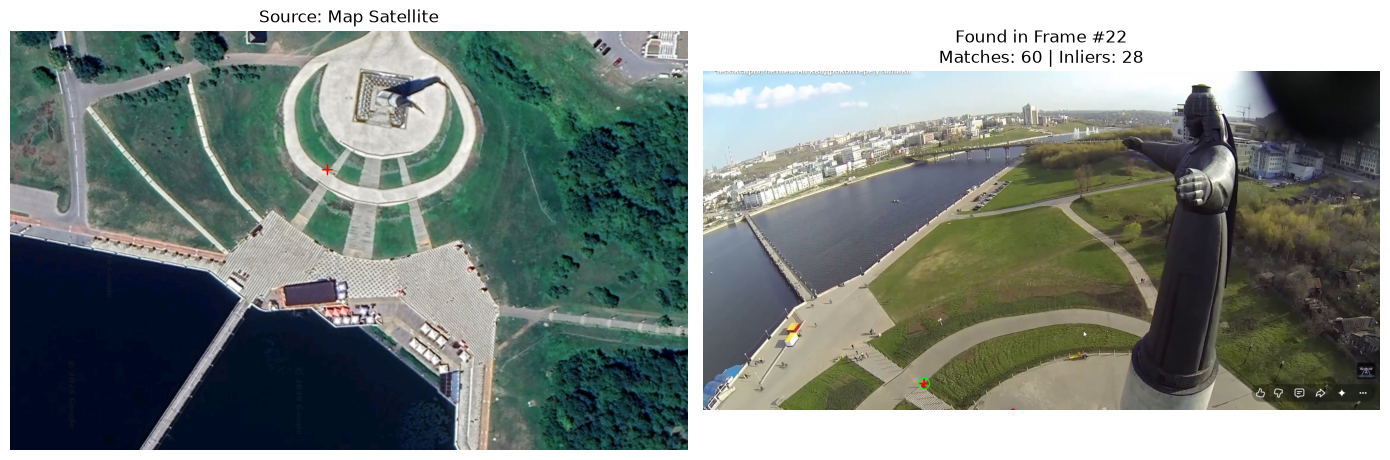

Using cache found in C:\Users\zhenu/.cache\torch\hub\facebookresearch_co-tracker_main
3/4:   0%|          | 0/403 [00:53<?, ?it/s]

[ВАЛІДАЦІЯ | Кадр 37] Кращий збіг з галереєю: 550 інлаєрів
[ЯКІР ВІДХИЛЕНО] Blur: 733.5 | Max Sim: 550


3/4:   0%|          | 0/403 [00:54<?, ?it/s]

[ВАЛІДАЦІЯ | Кадр 52] Кращий збіг з галереєю: 515 інлаєрів
[ЯКІР ВІДХИЛЕНО] Blur: 682.0 | Max Sim: 515


3/4:   0%|          | 0/403 [00:54<?, ?it/s]

[ВАЛІДАЦІЯ | Кадр 67] Кращий збіг з галереєю: 458 інлаєрів
[ЯКІР ВІДХИЛЕНО] Blur: 629.8 | Max Sim: 458


... (19 outputs left out)

[ВАЛІДАЦІЯ | Кадр 231] Кращий збіг з галереєю: 296 інлаєрів
[ЯКІР ВІДХИЛЕНО] Blur: 450.0 | Max Sim: 296


3/4:  59%|█████▉    | 238/403 [01:29<00:58,  2.81it/s]

[ВАЛІДАЦІЯ | Кадр 246] Кращий збіг з галереєю: 310 інлаєрів
[ЯКІР ВІДХИЛЕНО] Blur: 508.9 | Max Sim: 293


4/4: 100%|██████████| 425/425 [00:08<00:00, 49.91it/s]


In [5]:
import gc
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from lightglue import LightGlue, SuperPoint
from lightglue.utils import numpy_image_to_torch, rbd
from tqdm import tqdm

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_X = 640
TARGET_Y = 280
MIN_MATCHES = 18
MIN_INLIERS = 18       # Мінімальний базовий поріг інлаєрів для супутника
MAX_DIVERSITY_INLIERS = 100 # Поріг унікальності для якорів
ANCHOR_INTERVAL = 15      # Інтервал аналізу нових якорів
VALIDATION_INTERVAL = 15  # Інтервал перевірки чи не з'їхала точка

map_img = cv2.cvtColor(cv2.imread("map8.jpg"), cv2.COLOR_BGR2RGB)
target_sat_pt = np.array([[[float(TARGET_X), float(TARGET_Y)]]], dtype=np.float32)

extractor = SuperPoint(max_num_keypoints=2048).eval().to(device)
matcher = LightGlue(features='superpoint').eval().to(device)

with torch.no_grad():
    feats_sat = extractor.extract(numpy_image_to_torch(map_img).to(device))

cap = cv2.VideoCapture("fullReverse8.mp4")
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w_orig = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h_orig = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

found_start = False
start_frame_idx = 0
initial_x, initial_y = 0.0, 0.0
best_overall_inliers, best_overall_matches = -1, -1
best_initial_data = None
patience_counter = 0

rotations = [
    (0, None),
    (90, cv2.ROTATE_90_CLOCKWISE),
    (180, cv2.ROTATE_180),
    (270, cv2.ROTATE_90_COUNTERCLOCKWISE)
]

def map_rot_pt_to_orig(tx, ty, rot_code, w, h):
    if rot_code is None: return tx, ty
    elif rot_code == cv2.ROTATE_90_CLOCKWISE: return ty, h - tx
    elif rot_code == cv2.ROTATE_180: return w - tx, h - ty
    elif rot_code == cv2.ROTATE_90_COUNTERCLOCKWISE: return w - ty, tx
    return tx, ty

def get_ordered_anchor_indices(n):
    """Формує порядок перевірки якорів: [Останній, Перший, Решта з кінця]"""
    if n == 0: return []
    if n == 1: return [0]
    indices = [n - 1, 0]
    for i in range(n - 2, 0, -1):
        indices.append(i)
    return indices

def find_target_lightglue(frame_np, anchors_with_idx, rotations, extractor, matcher, device, proc_w, proc_h):
    best_in = -1
    best_nx, best_ny = 0.0, 0.0
    best_matches_cnt = 0
    best_anchor_img, best_anchor_pt_vis = None, None
    best_anchor_name = ""
    best_rot_match = None
    best_rot_code = None
    best_idx = 0
    best_kpts_curr_m = None
    best_kpts_anchor_m = None
    best_inliers_mask = None
    best_tx_rot, best_ty_rot = 0.0, 0.0

    rotated_frames = []
    for angle, rot_code in rotations:
        rot_np = cv2.rotate(frame_np, rot_code) if rot_code is not None else frame_np
        with torch.no_grad():
            feats_curr = extractor.extract(numpy_image_to_torch(rot_np).to(device))
        rotated_frames.append((angle, rot_code, rot_np, feats_curr))

    for a_idx, a_feats, a_pt, a_img, a_name in anchors_with_idx:
        for angle, rot_code, rot_np, feats_curr in rotated_frames:
            with torch.no_grad():
                matches_res = rbd(matcher({'image0': feats_curr, 'image1': a_feats}))
            matches = matches_res['matches']

            if len(matches) >= MIN_MATCHES:
                kpts_curr = feats_curr['keypoints'][0].cpu().numpy()
                kpts_anchor = a_feats['keypoints'][0].cpu().numpy()
                m_np = matches.cpu().numpy()

                H, inliers = cv2.findHomography(
                    kpts_curr[m_np[:, 0]], kpts_anchor[m_np[:, 1]], cv2.USAC_MAGSAC, 5.0
                )

                if H is not None:
                    val_in = int(np.sum(inliers))
                    if val_in > best_in:
                        H_inv = np.linalg.inv(H)
                        n_pt = cv2.perspectiveTransform(a_pt, H_inv)
                        tx, ty = n_pt[0][0][0], n_pt[0][0][1]
                        rw, rh = rot_np.shape[1], rot_np.shape[0]
                        if 0 <= tx <= rw and 0 <= ty <= rh:
                            orig_tx, orig_ty = map_rot_pt_to_orig(tx, ty, rot_code, proc_w, proc_h)
                            best_in = val_in
                            best_nx, best_ny = float(orig_tx), float(orig_ty)
                            best_tx_rot, best_ty_rot = float(tx), float(ty)
                            best_matches_cnt = len(matches)
                            best_anchor_img = a_img.copy() if a_img is not None else None
                            best_anchor_pt_vis = a_pt.copy()
                            best_anchor_name = a_name
                            best_rot_match = rot_np.copy()
                            best_rot_code = rot_code
                            best_idx = a_idx
                            best_kpts_curr_m = kpts_curr[m_np[:, 0]]
                            best_kpts_anchor_m = kpts_anchor[m_np[:, 1]]
                            best_inliers_mask = (inliers.ravel() == 1) if inliers is not None else None

    return (best_in, best_nx, best_ny, best_matches_cnt, best_anchor_img,
            best_anchor_pt_vis, best_anchor_name, best_rot_match, best_idx,
            best_kpts_curr_m, best_kpts_anchor_m, best_inliers_mask, best_tx_rot, best_ty_rot)

# --- ЕТАП 1: ІНІЦІАЛІЗАЦІЯ ---
for f_idx in tqdm(range(total_frames), desc="1/4"):
    ret, frame = cap.read()
    if not ret: break
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    best_inliers, best_frame_matches = -1, 0
    best_tx, best_ty = 0.0, 0.0
    best_frame_start = None

    with torch.no_grad():
        for angle, rot_code in rotations:
            rot_rgb = cv2.rotate(frame_rgb, rot_code) if rot_code is not None else frame_rgb
            feats_drone = extractor.extract(numpy_image_to_torch(rot_rgb).to(device))
            matches_res = rbd(matcher({'image0': feats_drone, 'image1': feats_sat}))
            matches = matches_res['matches']

            if len(matches) >= MIN_MATCHES:
                kpts_drone = feats_drone['keypoints'][0].cpu().numpy()
                kpts_sat = feats_sat['keypoints'][0].cpu().numpy()
                matches_np = matches.cpu().numpy()

                H, inliers_mask = cv2.findHomography(
                    kpts_drone[matches_np[:, 0]], kpts_sat[matches_np[:, 1]], cv2.USAC_MAGSAC, 5.0
                )
                if H is not None:
                    valid_inliers = int(np.sum(inliers_mask))
                    if valid_inliers > best_inliers:
                        H_inv = np.linalg.inv(H)
                        target_on_drone = cv2.perspectiveTransform(target_sat_pt, H_inv)
                        tx, ty = target_on_drone[0][0][0], target_on_drone[0][0][1]
                        rw, rh = rot_rgb.shape[1], rot_rgb.shape[0]
                        if 0 <= tx <= rw and 0 <= ty <= rh:
                            orig_tx, orig_ty = map_rot_pt_to_orig(tx, ty, rot_code, w_orig, h_orig)
                            best_inliers = valid_inliers
                            best_frame_matches = len(matches)
                            best_tx, best_ty = orig_tx, orig_ty
                            best_frame_start = frame_rgb.copy()

    if best_inliers >= MIN_INLIERS or found_start:
        if best_inliers > best_overall_inliers:
            best_overall_inliers = best_inliers
            best_overall_matches = best_frame_matches
            best_initial_data = (f_idx, best_tx, best_ty, best_frame_start.copy(), best_overall_matches)
            patience_counter = 0
            found_start = True
        elif found_start:
            patience_counter += 1

        if found_start and patience_counter >= 30:
            break

cap.release()

if not found_start:
    raise RuntimeError("Об'єкт не знайдено на Етапі 1!")

start_frame_idx, initial_x, initial_y, best_frame_start, initial_matches_cnt = best_initial_data

# === ВІЗУАЛІЗАЦІЯ СТАРТОВОГО КАДРУ ===
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
vis_map = map_img.copy()
cv2.drawMarker(vis_map, (int(TARGET_X), int(TARGET_Y)), (255, 0, 0), cv2.MARKER_CROSS, 20, 2)
vis_curr = best_frame_start.copy()
n_tx, n_ty = int(initial_x), int(initial_y)
cv2.drawMarker(vis_curr, (n_tx, n_ty), (255, 0, 0), cv2.MARKER_CROSS, 30, 3)
cv2.circle(vis_curr, (n_tx, n_ty), 15, (0, 255, 0), 2)
axes[0].imshow(vis_map)
axes[0].set_title("Source: Map Satellite")
axes[0].axis('off')
axes[1].imshow(vis_curr)
axes[1].set_title(f"Found in Frame #{start_frame_idx}\nMatches: {initial_matches_cnt} | Inliers: {best_overall_inliers}")
axes[1].axis('off')
plt.tight_layout()
plt.show()

proc_w, proc_h = 512, 288
scale_x = proc_w / w_orig
scale_y = proc_h / h_orig

initial_x_scaled = initial_x * scale_x
initial_y_scaled = initial_y * scale_y

hr_crop_size = 400
hr_half_c = hr_crop_size // 2

anchor_gallery = []

if best_frame_start is not None:
    y_min = max(0, int(initial_y) - hr_half_c)
    y_max = min(h_orig, int(initial_y) + hr_half_c)
    x_min = max(0, int(initial_x) - hr_half_c)
    x_max = min(w_orig, int(initial_x) + hr_half_c)
    first_crop = best_frame_start[y_min:y_max, x_min:x_max]

    with torch.no_grad():
        first_feats = extractor.extract(numpy_image_to_torch(first_crop).to(device))
    first_pt = np.array([[[initial_x - x_min, initial_y - y_min]]], dtype=np.float32)
    anchor_gallery.append((first_feats, first_pt, first_crop, "Master Anchor 0"))

cotracker = torch.hub.load("facebookresearch/co-tracker", "cotracker2").to(device)

cap = cv2.VideoCapture("fullReverse8.mp4")
frames_small = np.empty((total_frames, proc_h, proc_w, 3), dtype=np.uint8)

for i in tqdm(range(total_frames), desc="2/4"):
    ret, frame = cap.read()
    if not ret:
        total_frames = i
        frames_small = frames_small[:total_frames]
        break
    frames_small[i] = cv2.cvtColor(cv2.resize(frame, (proc_w, proc_h)), cv2.COLOR_BGR2RGB)
cap.release()

video_tensor_cpu = torch.from_numpy(frames_small).permute(0, 3, 1, 2).float().unsqueeze(0)
del frames_small
gc.collect()

cap_hr = cv2.VideoCapture("fullReverse8.mp4")

global_tracks = np.zeros((total_frames, 2), dtype=np.float32)
global_vis = np.zeros((total_frames,), dtype=bool)

curr_idx = start_frame_idx
tracking_active = True
curr_x, curr_y = float(initial_x_scaled), float(initial_y_scaled)
chunk_size = 120

last_anchor_frame_idx = start_frame_idx
failed_validation_counter = 0

redetect_found = False
redetect_patience = 0
best_redetect_inliers = -1
best_redetect_data = None

pbar_track = tqdm(total=total_frames - start_frame_idx, desc="3/4")

with torch.no_grad():
    while curr_idx < total_frames:
        if tracking_active:
            end_idx = min(curr_idx + chunk_size, total_frames)
            chunk_tensor = video_tensor_cpu[:, curr_idx:end_idx].to(device)
            query = torch.tensor([[[0.0, curr_x, curr_y]]]).float().to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                pred_tracks, pred_vis = cotracker(chunk_tensor, queries=query)

            tracks_np = pred_tracks[0, :, 0].cpu().numpy()
            vis_np = pred_vis[0, :, 0].cpu().numpy()

            chunk_len = len(vis_np)
            permanently_lost_idx = -1
            false_count = 0
            for idx in range(chunk_len):
                if not vis_np[idx]:
                    false_count += 1
                    if false_count >= 50 and permanently_lost_idx == -1:
                        permanently_lost_idx = idx - 50 + 1
                else:
                    false_count = 0

            if vis_np[-1] == False and permanently_lost_idx == -1:
                for idx in range(chunk_len - 1, -1, -1):
                    if vis_np[idx]:
                        permanently_lost_idx = idx + 1
                        break
                if permanently_lost_idx == -1: permanently_lost_idx = 0

            actual_len = chunk_len if end_idx == total_frames else chunk_len - 1
            is_lost = False

            if permanently_lost_idx != -1:
                actual_len = max(1, permanently_lost_idx)
                is_lost = True

            for step in range(1, actual_len):
                check_idx = curr_idx + step

                hr_cx = float(tracks_np[step, 0]) / scale_x
                hr_cy = float(tracks_np[step, 1]) / scale_y

                # =========================================================================
                # БЛОК ВАЛІДАЦІЇ: "Чи точка все ще на об'єкті?"
                # =========================================================================
                if step % VALIDATION_INTERVAL == 0:
                    cap_hr.set(cv2.CAP_PROP_POS_FRAMES, check_idx)
                    ret_hr, hr_frame_bgr = cap_hr.read()
                    if not ret_hr: continue
                    hr_frame_rgb = cv2.cvtColor(hr_frame_bgr, cv2.COLOR_BGR2RGB)

                    x_min = max(0, int(hr_cx) - hr_half_c)
                    y_min = max(0, int(hr_cy) - hr_half_c)
                    x_max = min(w_orig, int(hr_cx) + hr_half_c)
                    y_max = min(h_orig, int(hr_cy) + hr_half_c)

                    crop_rgb = hr_frame_rgb[y_min:y_max, x_min:x_max]

                    anchors_to_check = [(-1, feats_sat, target_sat_pt, map_img, "Map Satellite")]
                    for a_i in get_ordered_anchor_indices(len(anchor_gallery)):
                        a_data = anchor_gallery[a_i]
                        anchors_to_check.append((a_i, a_data[0], a_data[1], a_data[2], a_data[3]))

                    loc_in = find_target_lightglue(
                        crop_rgb, anchors_to_check, rotations, extractor, matcher, device, x_max - x_min, y_max - y_min
                    )[0]
                    loc_in = max(0, loc_in)

                    tqdm.write(f"[ВАЛІДАЦІЯ | Кадр {check_idx}] Кращий збіг з галереєю: {loc_in} інлаєрів")

                    if loc_in >= MIN_INLIERS:
                        failed_validation_counter = 0

                        if check_idx - last_anchor_frame_idx >= ANCHOR_INTERVAL:
                            blur_val = cv2.Laplacian(cv2.cvtColor(crop_rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()
                            candidate_feats = extractor.extract(numpy_image_to_torch(crop_rgb).to(device))
                            max_sim_inliers = 0

                            for a_i, anchor_data in enumerate(anchor_gallery):
                                val_res_sim = rbd(matcher({'image0': candidate_feats, 'image1': anchor_data[0]}))
                                m_sim = val_res_sim['matches']
                                sim_cnt = 0

                                if len(m_sim) >= 8:
                                    kpts_c = candidate_feats['keypoints'][0].cpu().numpy()
                                    kpts_a = anchor_data[0]['keypoints'][0].cpu().numpy()
                                    m_np_sim = m_sim.cpu().numpy()

                                    H_sim, inliers_sim = cv2.findHomography(
                                        kpts_c[m_np_sim[:, 0]], kpts_a[m_np_sim[:, 1]], cv2.USAC_MAGSAC, 5.0
                                    )
                                    if H_sim is not None:
                                        sim_cnt = int(np.sum(inliers_sim))
                                        if sim_cnt > max_sim_inliers: max_sim_inliers = sim_cnt

                            is_approved = (blur_val >= 30.0) and (max_sim_inliers < MAX_DIVERSITY_INLIERS)

                            if is_approved:
                                a_name = f"Anchor {len(anchor_gallery)} (Frame {check_idx})"
                                new_pt = np.array([[[hr_cx - x_min, hr_cy - y_min]]], dtype=np.float32)
                                anchor_gallery.append((candidate_feats, new_pt, crop_rgb, a_name))
                                last_anchor_frame_idx = check_idx
                                tqdm.write(f"\n[ЯКІР ДОДАНО] '{a_name}' | Blur: {blur_val:.1f} | Max Sim: {max_sim_inliers}")

                                if len(anchor_gallery) > 8:
                                    anchor_gallery.pop(1)
                            else:
                                tqdm.write(f"[ЯКІР ВІДХИЛЕНО] Blur: {blur_val:.1f} | Max Sim: {max_sim_inliers}")
                                last_anchor_frame_idx = check_idx

                    else:
                        failed_validation_counter += 1
                        tqdm.write(f"  >>> [ПОМИЛКА] Кроп не схожий на об'єкт ({loc_in} < {MIN_INLIERS}). Фейли: {failed_validation_counter}/3 <<<")

                        if failed_validation_counter >= 1:
                            tqdm.write(f"\n[КРИТИЧНО | Кадр {check_idx}] KILL SWITCH! Сповзання або перекриття. Втрата цілі.")
                            actual_len = step
                            is_lost = True
                            break

            global_tracks[curr_idx : curr_idx + actual_len] = tracks_np[:actual_len]
            global_vis[curr_idx : curr_idx + actual_len] = vis_np[:actual_len]

            if is_lost:
                tracking_active = False
                failed_validation_counter = 0
                last_anchor_frame_idx = curr_idx

                redetect_found = False
                redetect_patience = 0
                best_redetect_inliers = -1
                best_redetect_data = None

                pbar_track.update(actual_len)
                curr_idx += actual_len
            else:
                curr_x = float(tracks_np[actual_len - 1, 0])
                curr_y = float(tracks_np[actual_len - 1, 1])
                pbar_track.update(actual_len)
                curr_idx += actual_len

            del chunk_tensor
            torch.cuda.empty_cache()
        else:
            # =========================================================================
            # 3. РЕЖИМ ПЕРЕХОПЛЕННЯ (RE-DETECTION): СУПУТНИК -> ГАЛЕРЕЯ (+10)
            # =========================================================================
            cap_hr.set(cv2.CAP_PROP_POS_FRAMES, curr_idx)
            ret_hr, hr_frame_bgr = cap_hr.read()

            if ret_hr:
                hr_frame_rgb = cv2.cvtColor(hr_frame_bgr, cv2.COLOR_BGR2RGB)

                # 1. Перевірка ПОВНОГО супутникового зніму з порогом MIN_INLIERS
                sat_anchor = [(-1, feats_sat, target_sat_pt, map_img, "Map Satellite")]
                res_sat = find_target_lightglue(
                    hr_frame_rgb, sat_anchor, rotations, extractor, matcher, device, w_orig, h_orig
                )

                if res_sat[0] >= MIN_INLIERS:
                    res = res_sat
                    required_thresh = MIN_INLIERS
                else:
                    # 2. Якщо супутник не підійшов, перевіряємо якорі з галереї у порядку: [Останній, Перший, Решта з кінця]
                    anchors_200_to_check = []
                    lost_half_c = 100  # 200 // 2

                    for a_i in get_ordered_anchor_indices(len(anchor_gallery)):
                        a_feats, a_pt, a_img, a_name = anchor_gallery[a_i]
                        anc_x, anc_y = float(a_pt[0][0][0]), float(a_pt[0][0][1])

                        ax1 = max(0, int(anc_x) - lost_half_c)
                        ay1 = max(0, int(anc_y) - lost_half_c)
                        ax2 = min(a_img.shape[1], int(anc_x) + lost_half_c)
                        ay2 = min(a_img.shape[0], int(anc_y) + lost_half_c)

                        crop_200 = a_img[ay1:ay2, ax1:ax2]
                        pt_200 = np.array([[[anc_x - ax1, anc_y - ay1]]], dtype=np.float32)
                        feats_200 = extractor.extract(numpy_image_to_torch(crop_200).to(device))

                        anchors_200_to_check.append((a_i, feats_200, pt_200, crop_200, f"{a_name} (200x200)"))

                    res_gal = find_target_lightglue(
                        hr_frame_rgb, anchors_200_to_check, rotations, extractor, matcher, device, w_orig, h_orig
                    )
                    res = res_gal
                    required_thresh = MIN_INLIERS + 10

                best_in, best_nx, best_ny, _, _, _, best_anchor_name = res[:7]

                # Логіка накопичення найкращого кадру (Пейшенс 30)
                if best_in >= required_thresh or redetect_found:
                    if best_in > best_redetect_inliers:
                        best_redetect_inliers = best_in
                        best_redetect_data = (curr_idx, best_nx, best_ny, best_anchor_name)
                        redetect_patience = 0
                        redetect_found = True
                    elif redetect_found:
                        redetect_patience += 1

                    if redetect_found and redetect_patience >= 1:
                        best_f_idx, best_nx, best_ny, best_anchor_name = best_redetect_data

                        curr_idx = best_f_idx
                        curr_x = best_nx * scale_x
                        curr_y = best_ny * scale_y
                        tracking_active = True
                        last_anchor_frame_idx = curr_idx

                        tqdm.write(f"\n[ПЕРЕХОПЛЕННЯ УСПІШНЕ | Кадр {curr_idx}] Знайдено через '{best_anchor_name}' ({best_redetect_inliers} інлаєрів). Точка: ({best_nx:.1f}, {best_ny:.1f})")

                        redetect_found = False
                        redetect_patience = 0
                        best_redetect_inliers = -1
                        best_redetect_data = None
                    else:
                        pbar_track.update(1)
                        curr_idx += 1
                else:
                    pbar_track.update(1)
                    curr_idx += 1
            else:
                pbar_track.update(1)
                curr_idx += 1

pbar_track.close()
cap_hr.release()

del video_tensor_cpu, cotracker
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

global_tracks[:, 0] /= scale_x
global_tracks[:, 1] /= scale_y

# --- РЕНДЕРИНГ ВІДЕО ---
cap = cv2.VideoCapture("fullReverse8.mp4")
out = cv2.VideoWriter("output_test_full_smart_anchors_no_snap_8_final.mp4", cv2.VideoWriter_fourcc(*'mp4v'), 30, (w_orig, h_orig))

for i in tqdm(range(total_frames), desc="4/4"):
    ret, frame = cap.read()
    if not ret: break
    if global_vis[i]:
        x, y = int(global_tracks[i, 0]), int(global_tracks[i, 1])
        cv2.drawMarker(frame, (x, y), (0, 0, 255), cv2.MARKER_CROSS, 40, 3)
        cv2.circle(frame, (x, y), 20, (0, 255, 0), 3)
    out.write(frame)

cap.release()
out.release()

Використовується пристрій: cuda
Вилучення фіч із супутникової карти...

=== СТАРТ ФАЗИ 1 ПОШУКУ ===
Стартовий кадр: 0 | Кінцевий кадр: 1000


Обробка кадрів:  31%|███       | 311/1000 [01:18<03:09,  3.63it/s]

[ПІДТВЕРДЖЕНО] Кадр #0310 | Інлаєри: 18 | Матчі: 61 | Поворот: 270°
  └─► ОНОВЛЕНО КРАЩИЙ ЗБІГ! (Інлаєри: 18)


Обробка кадрів:  32%|███▏      | 315/1000 [01:19<03:08,  3.64it/s]

[ПІДТВЕРДЖЕНО] Кадр #0314 | Інлаєри: 22 | Матчі: 71 | Поворот: 270°
  └─► ОНОВЛЕНО КРАЩИЙ ЗБІГ! (Інлаєри: 22)


Обробка кадрів:  32%|███▏      | 316/1000 [01:19<03:07,  3.64it/s]

... (443 outputs left out)

Обробка кадрів:  94%|█████████▍| 945/1000 [04:24<00:16,  3.36it/s]

[ПІДТВЕРДЖЕНО] Кадр #0944 | Інлаєри: 19 | Матчі: 101 | Поворот: 0°


Обробка кадрів: 100%|██████████| 1000/1000 [04:40<00:00,  3.56it/s]



ПІДСУМОК ПОШУКУ ФАЗИ 1:
  • Кращий кадр #:        613
  • Оптимальний кут:      270°
  • Матчів у кращому:     111
  • Інлаєрів у кращому:   47
  • Координати цілі:      X=658.9, Y=539.9
  • Відео збережено у:    output_phase1_search.mp4


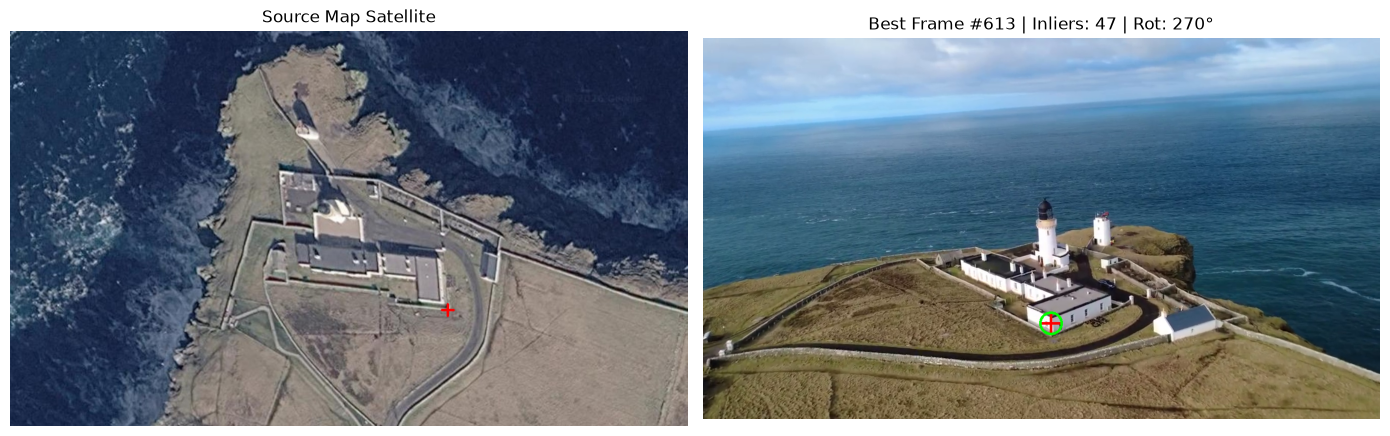

In [4]:
import cv2
import torch
import numpy as np
import gc
import matplotlib.pyplot as plt
from lightglue import LightGlue, SuperPoint
from lightglue.utils import numpy_image_to_torch, rbd
from tqdm import tqdm

# --- ОЧИЩЕННЯ ПАМ'ЯТІ ---
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Використовується пристрій: {device}")

# =========================================================================
# НАЛАШТУВАННЯ ТА ПАРАМЕТРИ
# =========================================================================
TARGET_X = 870
TARGET_Y = 555
MIN_MATCHES = 18
MIN_INLIERS = 18       # Поріг для підтвердження цілі

# ПАРАМЕТР СТАРТУ (START_FRAME):
#  • Якщо None (або np.nan) — починає з першого кадру (0)
#  • Якщо число (наприклад, 100) — починає обробку з кадру №100
START_FRAME = None

# ПАРАМЕТР ЗУПИНКИ (STOP_FRAME):
#  • Якщо None (або np.nan) — іде по всьому відео / до підтвердження об'єкта
#  • Якщо число (наприклад, 150) — зупиняє аналіз строго на цьому кадрі
STOP_FRAME = 1000

# Завантаження супутникової карти
map_bgr = cv2.imread("map7.jpg")
map_img_rgb = cv2.cvtColor(map_bgr, cv2.COLOR_BGR2RGB)
target_sat_pt = np.array([[[float(TARGET_X), float(TARGET_Y)]]], dtype=np.float32)

extractor = SuperPoint(max_num_keypoints=2048).eval().to(device)
matcher = LightGlue(features='superpoint').eval().to(device)

print("Вилучення фіч із супутникової карти...")
with torch.no_grad():
    feats_sat = extractor.extract(numpy_image_to_torch(map_img_rgb).to(device))

video_path = "fullReverse7.mp4"
cap = cv2.VideoCapture(video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w_orig = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h_orig = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Масштабування карти праворуч під висоту кадру дрона h_orig
map_h_raw, map_w_raw = map_bgr.shape[:2]
scale_map = h_orig / float(map_h_raw)
map_w_disp = int(map_w_raw * scale_map)
map_disp_bgr = cv2.resize(map_bgr, (map_w_disp, h_orig))

# Загальний розмір відеополотна (Side-by-Side: Дрон ліворуч, Карта праворуч)
canvas_w = w_orig + map_w_disp
canvas_h = h_orig

rotations = [
    (0, None),
    (90, cv2.ROTATE_90_CLOCKWISE),
    (180, cv2.ROTATE_180),
    (270, cv2.ROTATE_90_COUNTERCLOCKWISE)
]

def map_rot_pt_to_orig(tx, ty, rot_code, w, h):
    """Переведення координат з повернутого кадру в оригінальну систему координат відео"""
    if rot_code is None: return tx, ty
    elif rot_code == cv2.ROTATE_90_CLOCKWISE: return ty, h - tx
    elif rot_code == cv2.ROTATE_180: return w - tx, h - ty
    elif rot_code == cv2.ROTATE_90_COUNTERCLOCKWISE: return w - ty, tx
    return tx, ty

# Визначення стартового та кінцевого кадру
if START_FRAME is None or (isinstance(START_FRAME, float) and np.isnan(START_FRAME)):
    start_frame_idx = 0
else:
    start_frame_idx = max(0, int(START_FRAME))

if STOP_FRAME is None or (isinstance(STOP_FRAME, float) and np.isnan(STOP_FRAME)):
    max_search_frames = total_frames
else:
    max_search_frames = min(int(STOP_FRAME), total_frames)

# Встановлюємо позицію відео на стартовий кадр
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame_idx)

out_video = cv2.VideoWriter(
    "output_phase1_search7.mp4",
    cv2.VideoWriter_fourcc(*'mp4v'),
    int(fps),
    (canvas_w, canvas_h)
)

found_start = False
best_overall_inliers = -1
best_overall_matches = -1
best_initial_data = None
patience_counter = 0

print(f"\n=== СТАРТ ФАЗИ 1 ПОШУКУ ===")
print(f"Стартовий кадр: {start_frame_idx} | Кінцевий кадр: {max_search_frames}")

for f_idx in tqdm(range(start_frame_idx, max_search_frames), desc="Обробка кадрів"):
    ret, frame = cap.read()
    if not ret:
        break

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    best_frame_inliers = -1
    best_frame_matches = 0
    best_orig_tx, best_orig_ty = None, None
    best_angle = 0
    best_rot_code = None
    best_matches_info = None  # Зберігаємо деталі кращого матчингу

    with torch.no_grad():
        for angle, rot_code in rotations:
            rot_rgb = cv2.rotate(frame_rgb, rot_code) if rot_code is not None else frame_rgb
            feats_drone = extractor.extract(numpy_image_to_torch(rot_rgb).to(device))
            matches_res = rbd(matcher({'image0': feats_drone, 'image1': feats_sat}))
            matches = matches_res['matches']

            if len(matches) >= 4:
                kpts_drone = feats_drone['keypoints'][0].cpu().numpy()
                kpts_sat = feats_sat['keypoints'][0].cpu().numpy()
                matches_np = matches.cpu().numpy()

                H, inliers_mask = cv2.findHomography(
                    kpts_drone[matches_np[:, 0]],
                    kpts_sat[matches_np[:, 1]],
                    method=cv2.USAC_MAGSAC,
                    ransacReprojThreshold=5.0,
                    maxIters=2000,
                    confidence=0.995
                )
                if H is not None:
                    valid_inliers = int(np.sum(inliers_mask))
                    if valid_inliers > best_frame_inliers:
                        H_inv = np.linalg.inv(H)
                        target_on_drone = cv2.perspectiveTransform(target_sat_pt, H_inv)
                        tx, ty = target_on_drone[0][0][0], target_on_drone[0][0][1]
                        rw, rh = rot_rgb.shape[1], rot_rgb.shape[0]

                        if 0 <= tx <= rw and 0 <= ty <= rh:
                            orig_tx, orig_ty = map_rot_pt_to_orig(tx, ty, rot_code, w_orig, h_orig)
                            best_frame_inliers = valid_inliers
                            best_frame_matches = len(matches)
                            best_orig_tx, best_orig_ty = orig_tx, orig_ty
                            best_angle = angle
                            best_rot_code = rot_code

                            best_matches_info = {
                                'kpts_drone': kpts_drone[matches_np[:, 0]],
                                'kpts_sat': kpts_sat[matches_np[:, 1]],
                                'inliers_mask': (inliers_mask.ravel() == 1),
                                'rot_code': rot_code
                            }

    # --- ФОРМУВАННЯ ПОЛОТНА ВІДЕО (ДРОН ЛІВОРУЧ, КАРТА ПРАВОРУЧ) ---
    canvas = np.zeros((canvas_h, canvas_w, 3), dtype=np.uint8)
    canvas[0:h_orig, 0:w_orig] = frame.copy()
    canvas[0:h_orig, w_orig:canvas_w] = map_disp_bgr.copy()

    # 1. Малюємо ціль на супутниковій карті (праворуч)
    sat_target_x_disp = int(TARGET_X * scale_map) + w_orig
    sat_target_y_disp = int(TARGET_Y * scale_map)
    cv2.drawMarker(canvas, (sat_target_x_disp, sat_target_y_disp), (255, 0, 0), cv2.MARKER_CROSS, 25, 2)
    cv2.circle(canvas, (sat_target_x_disp, sat_target_y_disp), 12, (255, 0, 0), 2)

    # 2. МАТЧІ: ІНЛАЄРИ (зелені лінії) ТА ПРОСТІ МАТЧІ (маленькі червоні цятки без ліній)
    if best_matches_info is not None:
        kpts_d = best_matches_info['kpts_drone']
        kpts_s = best_matches_info['kpts_sat']
        mask = best_matches_info['inliers_mask']
        rot_c = best_matches_info['rot_code']

        for m_i in range(len(kpts_d)):
            # Точка на оригінальному кадрі дрона
            d_orig_x, d_orig_y = map_rot_pt_to_orig(kpts_d[m_i][0], kpts_d[m_i][1], rot_c, w_orig, h_orig)
            pt_drone = (int(d_orig_x), int(d_orig_y))

            if mask[m_i]:
                # === ІНЛАЄР (ЗЕЛЕНИЙ): Малюємо зелену лінію та точки з обох боків ===
                s_disp_x = int(kpts_s[m_i][0] * scale_map) + w_orig
                s_disp_y = int(kpts_s[m_i][1] * scale_map)
                pt_sat = (s_disp_x, s_disp_y)

                cv2.line(canvas, pt_drone, pt_sat, (0, 255, 0), 2, cv2.LINE_AA)
                cv2.circle(canvas, pt_drone, 4, (0, 255, 0), -1)
                cv2.circle(canvas, pt_sat, 4, (0, 255, 0), -1)
            else:
                # === ПРОСТИЙ МАТЧ / АУТЛАЄР (ЧЕРВОНИЙ): Малюємо тільки мінімальну червону цятку без ліній ===
                cv2.circle(canvas, pt_drone, 1, (0, 0, 255), -1)

    # 3. Малюємо прогнозовану ціль на кадрі дрона (ліворуч)
    if best_orig_tx is not None and best_orig_ty is not None:
        t_x, t_y = int(best_orig_tx), int(best_orig_ty)

        is_confirmed = (best_frame_inliers >= MIN_INLIERS)
        target_color = (0, 255, 0) if is_confirmed else (0, 255, 255)
        label_text = "CONFIRMED TARGET" if is_confirmed else "CANDIDATE TARGET"

        cv2.drawMarker(canvas, (t_x, t_y), target_color, cv2.MARKER_CROSS, 35, 3)
        cv2.circle(canvas, (t_x, t_y), 18, target_color, 2)
        cv2.putText(canvas, f"{label_text} ({t_x},{t_y})", (max(10, t_x + 15), max(30, t_y - 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, target_color, 2)

    # 4. Текстова плашка зі статистикою
    status_str = f"Frame {f_idx:04d} | Best Rot: {best_angle} deg | Inliers: {max(0, best_frame_inliers)} | Matches: {best_frame_matches}"
    status_color = (0, 255, 0) if best_frame_inliers >= MIN_INLIERS else (0, 255, 255) if best_frame_inliers > 0 else (0, 0, 255)

    cv2.rectangle(canvas, (10, 10), (canvas_w - 10, 60), (0, 0, 0), -1)
    cv2.putText(canvas, status_str, (20, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.8, status_color, 2, cv2.LINE_AA)

    out_video.write(canvas)

    # Збереження кращого результату
    if best_frame_inliers >= MIN_INLIERS:
        tqdm.write(f"[ПІДТВЕРДЖЕНО] Кадр #{f_idx:04d} | Інлаєри: {best_frame_inliers:02d} | Матчі: {best_frame_matches:02d} | Поворот: {best_angle}°")

        if best_frame_inliers > best_overall_inliers:
            best_overall_inliers = best_frame_inliers
            best_overall_matches = best_frame_matches
            best_initial_data = (f_idx, best_orig_tx, best_orig_ty, frame_rgb.copy(), best_overall_matches, best_angle)
            patience_counter = 0
            found_start = True
            tqdm.write(f"  └─► ОНОВЛЕНО КРАЩИЙ ЗБІГ! (Інлаєри: {best_overall_inliers})")
        elif found_start:
            patience_counter += 1
    elif found_start:
        patience_counter += 1

    # Вихід, якщо STOP_FRAME не заданий і знайдено стійкий збіг
    if STOP_FRAME is None and found_start and patience_counter >= 5:
        tqdm.write(f"\nЗнайдено надійну ціль. Пошук завершено на кадрі #{f_idx}.")
        break

cap.release()
out_video.release()

if not found_start:
    print("\n[УВАГА] Підтвердженої цілі (з >= MIN_INLIERS) не знайдено!")
else:
    start_frame_idx, initial_x, initial_y, best_frame_start, matches_cnt, angle_found = best_initial_data
    print("\n" + "="*50)
    print("ПІДСУМОК ПОШУКУ ФАЗИ 1:")
    print(f"  • Кращий кадр #:        {start_frame_idx}")
    print(f"  • Оптимальний кут:      {angle_found}°")
    print(f"  • Матчів у кращому:     {matches_cnt}")
    print(f"  • Інлаєрів у кращому:   {best_overall_inliers}")
    print(f"  • Координати цілі:      X={initial_x:.1f}, Y={initial_y:.1f}")
    print(f"  • Відео збережено у:    output_phase1_search.mp4")
    print("="*50)

    # Показ фінального вікна зі збігом
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    vis_map = map_img_rgb.copy()
    cv2.drawMarker(vis_map, (int(TARGET_X), int(TARGET_Y)), (255, 0, 0), cv2.MARKER_CROSS, 25, 3)

    vis_curr = best_frame_start.copy()
    n_tx, n_ty = int(initial_x), int(initial_y)
    cv2.drawMarker(vis_curr, (n_tx, n_ty), (255, 0, 0), cv2.MARKER_CROSS, 35, 3)
    cv2.circle(vis_curr, (n_tx, n_ty), 20, (0, 255, 0), 3)

    axes[0].imshow(vis_map)
    axes[0].set_title("Source Map Satellite")
    axes[0].axis('off')

    axes[1].imshow(vis_curr)
    axes[1].set_title(f"Best Frame #{start_frame_idx} | Inliers: {best_overall_inliers} | Rot: {angle_found}°")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

In [6]:
import cv2
import torch
import numpy as np
import gc
import matplotlib.pyplot as plt
from lightglue import LightGlue, SuperPoint
from lightglue.utils import numpy_image_to_torch, rbd
from tqdm import tqdm

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TARGET_X = 940
TARGET_Y = 480
MIN_MATCHES = 18
MIN_INLIERS = 18       # Мінімальний базовий поріг інлаєрів для супутника
MAX_DIVERSITY_INLIERS = 100 # Поріг унікальності для якорів
ANCHOR_INTERVAL = 15      # Інтервал аналізу нових якорів
VALIDATION_INTERVAL = 15  # Інтервал перевірки чи не з'їхала точка

map_img = cv2.cvtColor(cv2.imread("map8.jpg"), cv2.COLOR_BGR2RGB)
target_sat_pt = np.array([[[float(TARGET_X), float(TARGET_Y)]]], dtype=np.float32)

extractor = SuperPoint(max_num_keypoints=2048).eval().to(device)
matcher = LightGlue(features='superpoint').eval().to(device)

with torch.no_grad():
    feats_sat = extractor.extract(numpy_image_to_torch(map_img).to(device))

cap = cv2.VideoCapture("fullReverse8.mp4")
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w_orig = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h_orig = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

found_start = False
start_frame_idx = 0
initial_x, initial_y = 0.0, 0.0
best_overall_inliers, best_overall_matches = -1, -1
best_initial_data = None
patience_counter = 0

rotations = [
    (0, None),
    (90, cv2.ROTATE_90_CLOCKWISE),
    (180, cv2.ROTATE_180),
    (270, cv2.ROTATE_90_COUNTERCLOCKWISE)
]

def map_rot_pt_to_orig(tx, ty, rot_code, w, h):
    if rot_code is None: return tx, ty
    elif rot_code == cv2.ROTATE_90_CLOCKWISE: return ty, h - tx
    elif rot_code == cv2.ROTATE_180: return w - tx, h - ty
    elif rot_code == cv2.ROTATE_90_COUNTERCLOCKWISE: return w - ty, tx
    return tx, ty

def get_ordered_anchor_indices(n):
    """Формує порядок перевірки якорів: [Останній, Перший, Решта з кінця]"""
    if n == 0: return []
    if n == 1: return [0]
    indices = [n - 1, 0]
    for i in range(n - 2, 0, -1):
        indices.append(i)
    return indices

def find_target_lightglue(frame_np, anchors_with_idx, rotations, extractor, matcher, device, proc_w, proc_h):
    best_in = -1
    best_nx, best_ny = 0.0, 0.0
    best_matches_cnt = 0
    best_anchor_img, best_anchor_pt_vis = None, None
    best_anchor_name = ""
    best_rot_match = None
    best_rot_code = None
    best_idx = 0
    best_kpts_curr_m = None
    best_kpts_anchor_m = None
    best_inliers_mask = None
    best_tx_rot, best_ty_rot = 0.0, 0.0
    best_angle = 0

    rotated_frames = []
    for angle, rot_code in rotations:
        rot_np = cv2.rotate(frame_np, rot_code) if rot_code is not None else frame_np
        with torch.no_grad():
            feats_curr = extractor.extract(numpy_image_to_torch(rot_np).to(device))
        rotated_frames.append((angle, rot_code, rot_np, feats_curr))

    for a_idx, a_feats, a_pt, a_img, a_name in anchors_with_idx:
        for angle, rot_code, rot_np, feats_curr in rotated_frames:
            with torch.no_grad():
                matches_res = rbd(matcher({'image0': feats_curr, 'image1': a_feats}))
            matches = matches_res['matches']

            if len(matches) >= MIN_MATCHES:
                kpts_curr = feats_curr['keypoints'][0].cpu().numpy()
                kpts_anchor = a_feats['keypoints'][0].cpu().numpy()
                m_np = matches.cpu().numpy()

                H, inliers = cv2.findHomography(
                    kpts_curr[m_np[:, 0]], kpts_anchor[m_np[:, 1]], cv2.USAC_MAGSAC, 5.0
                )

                if H is not None:
                    val_in = int(np.sum(inliers))
                    if val_in > best_in:
                        H_inv = np.linalg.inv(H)
                        n_pt = cv2.perspectiveTransform(a_pt, H_inv)
                        tx, ty = n_pt[0][0][0], n_pt[0][0][1]
                        rw, rh = rot_np.shape[1], rot_np.shape[0]
                        if 0 <= tx <= rw and 0 <= ty <= rh:
                            orig_tx, orig_ty = map_rot_pt_to_orig(tx, ty, rot_code, proc_w, proc_h)
                            best_in = val_in
                            best_nx, best_ny = float(orig_tx), float(orig_ty)
                            best_tx_rot, best_ty_rot = float(tx), float(ty)
                            best_matches_cnt = len(matches)
                            best_anchor_img = a_img.copy() if a_img is not None else None
                            best_anchor_pt_vis = a_pt.copy()
                            best_anchor_name = a_name
                            best_rot_match = rot_np.copy()
                            best_rot_code = rot_code
                            best_angle = angle
                            best_idx = a_idx
                            best_kpts_curr_m = kpts_curr[m_np[:, 0]]
                            best_kpts_anchor_m = kpts_anchor[m_np[:, 1]]
                            best_inliers_mask = (inliers.ravel() == 1) if inliers is not None else None

    return (best_in, best_nx, best_ny, best_matches_cnt, best_anchor_img,
            best_anchor_pt_vis, best_anchor_name, best_rot_match, best_idx,
            best_kpts_curr_m, best_kpts_anchor_m, best_inliers_mask, best_tx_rot, best_ty_rot, best_rot_code, best_angle)

# --- ЕТАП 1: ІНІЦІАЛІЗАЦІЯ ---
for f_idx in tqdm(range(total_frames), desc="1/4"):
    ret, frame = cap.read()
    if not ret: break
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    best_inliers, best_frame_matches = -1, 0
    best_tx, best_ty = 0.0, 0.0
    best_frame_start = None

    with torch.no_grad():
        for angle, rot_code in rotations:
            rot_rgb = cv2.rotate(frame_rgb, rot_code) if rot_code is not None else frame_rgb
            feats_drone = extractor.extract(numpy_image_to_torch(rot_rgb).to(device))
            matches_res = rbd(matcher({'image0': feats_drone, 'image1': feats_sat}))
            matches = matches_res['matches']

            if len(matches) >= MIN_MATCHES:
                kpts_drone = feats_drone['keypoints'][0].cpu().numpy()
                kpts_sat = feats_sat['keypoints'][0].cpu().numpy()
                matches_np = matches.cpu().numpy()

                H, inliers_mask = cv2.findHomography(
                    kpts_drone[matches_np[:, 0]], kpts_sat[matches_np[:, 1]], cv2.USAC_MAGSAC, 5.0
                )
                if H is not None:
                    valid_inliers = int(np.sum(inliers_mask))
                    if valid_inliers > best_inliers:
                        H_inv = np.linalg.inv(H)
                        target_on_drone = cv2.perspectiveTransform(target_sat_pt, H_inv)
                        tx, ty = target_on_drone[0][0][0], target_on_drone[0][0][1]
                        rw, rh = rot_rgb.shape[1], rot_rgb.shape[0]
                        if 0 <= tx <= rw and 0 <= ty <= rh:
                            orig_tx, orig_ty = map_rot_pt_to_orig(tx, ty, rot_code, w_orig, h_orig)
                            best_inliers = valid_inliers
                            best_frame_matches = len(matches)
                            best_tx, best_ty = orig_tx, orig_ty
                            best_frame_start = frame_rgb.copy()

    if best_inliers >= MIN_INLIERS or found_start:
        if best_inliers > best_overall_inliers:
            best_overall_inliers = best_inliers
            best_overall_matches = best_frame_matches
            best_initial_data = (f_idx, best_tx, best_ty, best_frame_start.copy(), best_overall_matches)
            patience_counter = 0
            found_start = True
        elif found_start:
            patience_counter += 1

        if found_start and patience_counter >= 30:
            break

cap.release()

if not found_start:
    raise RuntimeError("Об'єкт не знайдено на Етапі 1!")

start_frame_idx, initial_x, initial_y, best_frame_start, initial_matches_cnt = best_initial_data

# === ВІЗУАЛІЗАЦІЯ СТАРТОВОГО КАДРУ ===
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
vis_map = map_img.copy()
cv2.drawMarker(vis_map, (int(TARGET_X), int(TARGET_Y)), (255, 0, 0), cv2.MARKER_CROSS, 20, 2)
vis_curr = best_frame_start.copy()
n_tx, n_ty = int(initial_x), int(initial_y)
cv2.drawMarker(vis_curr, (n_tx, n_ty), (255, 0, 0), cv2.MARKER_CROSS, 30, 3)
cv2.circle(vis_curr, (n_tx, n_ty), 15, (0, 255, 0), 2)
axes[0].imshow(vis_map)
axes[0].set_title("Source: Map Satellite")
axes[0].axis('off')
axes[1].imshow(vis_curr)
axes[1].set_title(f"Found in Frame #{start_frame_idx}\nMatches: {initial_matches_cnt} | Inliers: {best_overall_inliers}")
axes[1].axis('off')
plt.tight_layout()
plt.show()

proc_w, proc_h = 512, 288
scale_x = proc_w / w_orig
scale_y = proc_h / h_orig

initial_x_scaled = initial_x * scale_x
initial_y_scaled = initial_y * scale_y

hr_crop_size = 400
hr_half_c = hr_crop_size // 2

anchor_gallery = []

if best_frame_start is not None:
    y_min = max(0, int(initial_y) - hr_half_c)
    y_max = min(h_orig, int(initial_y) + hr_half_c)
    x_min = max(0, int(initial_x) - hr_half_c)
    x_max = min(w_orig, int(initial_x) + hr_half_c)
    first_crop = best_frame_start[y_min:y_max, x_min:x_max]

    with torch.no_grad():
        first_feats = extractor.extract(numpy_image_to_torch(first_crop).to(device))
    first_pt = np.array([[[initial_x - x_min, initial_y - y_min]]], dtype=np.float32)
    anchor_gallery.append((first_feats, first_pt, first_crop, "Master Anchor 0"))

cotracker = torch.hub.load("facebookresearch/co-tracker", "cotracker2").to(device)

cap = cv2.VideoCapture("fullReverse8.mp4")
frames_small = np.empty((total_frames, proc_h, proc_w, 3), dtype=np.uint8)

for i in tqdm(range(total_frames), desc="2/4"):
    ret, frame = cap.read()
    if not ret:
        total_frames = i
        frames_small = frames_small[:total_frames]
        break
    frames_small[i] = cv2.cvtColor(cv2.resize(frame, (proc_w, proc_h)), cv2.COLOR_BGR2RGB)
cap.release()

video_tensor_cpu = torch.from_numpy(frames_small).permute(0, 3, 1, 2).float().unsqueeze(0)
del frames_small
gc.collect()

cap_hr = cv2.VideoCapture("fullReverse8.mp4")

global_tracks = np.zeros((total_frames, 2), dtype=np.float32)
global_vis = np.zeros((total_frames,), dtype=bool)

redetect_debug_info = {}

curr_idx = start_frame_idx
tracking_active = True
curr_x, curr_y = float(initial_x_scaled), float(initial_y_scaled)
chunk_size = 120

last_anchor_frame_idx = start_frame_idx
failed_validation_counter = 0

redetect_found = False
redetect_patience = 0
best_redetect_inliers = -1
best_redetect_data = None

pbar_track = tqdm(total=total_frames - start_frame_idx, desc="3/4")

with torch.no_grad():
    while curr_idx < total_frames:
        if tracking_active:
            end_idx = min(curr_idx + chunk_size, total_frames)
            chunk_tensor = video_tensor_cpu[:, curr_idx:end_idx].to(device)
            query = torch.tensor([[[0.0, curr_x, curr_y]]]).float().to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                pred_tracks, pred_vis = cotracker(chunk_tensor, queries=query)

            tracks_np = pred_tracks[0, :, 0].cpu().numpy()
            vis_np = pred_vis[0, :, 0].cpu().numpy()

            chunk_len = len(vis_np)
            permanently_lost_idx = -1
            false_count = 0
            for idx in range(chunk_len):
                if not vis_np[idx]:
                    false_count += 1
                    if false_count >= 50 and permanently_lost_idx == -1:
                        permanently_lost_idx = idx - 50 + 1
                else:
                    false_count = 0

            if vis_np[-1] == False and permanently_lost_idx == -1:
                for idx in range(chunk_len - 1, -1, -1):
                    if vis_np[idx]:
                        permanently_lost_idx = idx + 1
                        break
                if permanently_lost_idx == -1: permanently_lost_idx = 0

            actual_len = chunk_len if end_idx == total_frames else chunk_len - 1
            is_lost = False

            if permanently_lost_idx != -1:
                actual_len = max(1, permanently_lost_idx)
                is_lost = True

            for step in range(1, actual_len):
                check_idx = curr_idx + step

                hr_cx = float(tracks_np[step, 0]) / scale_x
                hr_cy = float(tracks_np[step, 1]) / scale_y

                # =========================================================================
                # БЛОК ВАЛІДАЦІЇ: "Чи точка все ще на об'єкті?"
                # =========================================================================
                if step % VALIDATION_INTERVAL == 0:
                    cap_hr.set(cv2.CAP_PROP_POS_FRAMES, check_idx)
                    ret_hr, hr_frame_bgr = cap_hr.read()
                    if not ret_hr: continue
                    hr_frame_rgb = cv2.cvtColor(hr_frame_bgr, cv2.COLOR_BGR2RGB)

                    x_min = max(0, int(hr_cx) - hr_half_c)
                    y_min = max(0, int(hr_cy) - hr_half_c)
                    x_max = min(w_orig, int(hr_cx) + hr_half_c)
                    y_max = min(h_orig, int(hr_cy) + hr_half_c)

                    crop_rgb = hr_frame_rgb[y_min:y_max, x_min:x_max]

                    anchors_to_check = [(-1, feats_sat, target_sat_pt, map_img, "Map Satellite")]
                    for a_i in get_ordered_anchor_indices(len(anchor_gallery)):
                        a_data = anchor_gallery[a_i]
                        anchors_to_check.append((a_i, a_data[0], a_data[1], a_data[2], a_data[3]))

                    loc_in = find_target_lightglue(
                        crop_rgb, anchors_to_check, rotations, extractor, matcher, device, x_max - x_min, y_max - y_min
                    )[0]
                    loc_in = max(0, loc_in)

                    tqdm.write(f"[ВАЛІДАЦІЯ | Кадр {check_idx}] Кращий збіг з галереєю: {loc_in} інлаєрів")

                    if loc_in >= MIN_INLIERS:
                        failed_validation_counter = 0

                        if check_idx - last_anchor_frame_idx >= ANCHOR_INTERVAL:
                            blur_val = cv2.Laplacian(cv2.cvtColor(crop_rgb, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var()
                            candidate_feats = extractor.extract(numpy_image_to_torch(crop_rgb).to(device))
                            max_sim_inliers = 0

                            for a_i, anchor_data in enumerate(anchor_gallery):
                                val_res_sim = rbd(matcher({'image0': candidate_feats, 'image1': anchor_data[0]}))
                                m_sim = val_res_sim['matches']
                                sim_cnt = 0

                                if len(m_sim) >= 8:
                                    kpts_c = candidate_feats['keypoints'][0].cpu().numpy()
                                    kpts_a = anchor_data[0]['keypoints'][0].cpu().numpy()
                                    m_np_sim = m_sim.cpu().numpy()

                                    H_sim, inliers_sim = cv2.findHomography(
                                        kpts_c[m_np_sim[:, 0]], kpts_a[m_np_sim[:, 1]], cv2.USAC_MAGSAC, 5.0
                                    )
                                    if H_sim is not None:
                                        sim_cnt = int(np.sum(inliers_sim))
                                        if sim_cnt > max_sim_inliers: max_sim_inliers = sim_cnt

                            is_approved = (blur_val >= 30.0) and (max_sim_inliers < MAX_DIVERSITY_INLIERS)

                            if is_approved:
                                a_name = f"Anchor {len(anchor_gallery)} (Frame {check_idx})"
                                new_pt = np.array([[[hr_cx - x_min, hr_cy - y_min]]], dtype=np.float32)
                                anchor_gallery.append((candidate_feats, new_pt, crop_rgb, a_name))
                                last_anchor_frame_idx = check_idx
                                tqdm.write(f"\n[ЯКІР ДОДАНО] '{a_name}' | Blur: {blur_val:.1f} | Max Sim: {max_sim_inliers}")

                                if len(anchor_gallery) > 8:
                                    anchor_gallery.pop(1)
                            else:
                                tqdm.write(f"[ЯКІР ВІДХИЛЕНО] Blur: {blur_val:.1f} | Max Sim: {max_sim_inliers}")
                                last_anchor_frame_idx = check_idx

                    else:
                        failed_validation_counter += 1
                        tqdm.write(f"  >>> [ПОМИЛКА] Кроп не схожий на об'єкт ({loc_in} < {MIN_INLIERS}). Фейли: {failed_validation_counter}/3 <<<")

                        if failed_validation_counter >= 1:
                            tqdm.write(f"\n[КРИТИЧНО | Кадр {check_idx}] KILL SWITCH! Сповзання або перекриття. Втрата цілі.")
                            actual_len = step
                            is_lost = True
                            break

            global_tracks[curr_idx : curr_idx + actual_len] = tracks_np[:actual_len]
            global_vis[curr_idx : curr_idx + actual_len] = vis_np[:actual_len]

            if is_lost:
                tracking_active = False
                failed_validation_counter = 0
                last_anchor_frame_idx = curr_idx

                redetect_found = False
                redetect_patience = 0
                best_redetect_inliers = -1
                best_redetect_data = None

                pbar_track.update(actual_len)
                curr_idx += actual_len
            else:
                curr_x = float(tracks_np[actual_len - 1, 0])
                curr_y = float(tracks_np[actual_len - 1, 1])
                pbar_track.update(actual_len)
                curr_idx += actual_len

            del chunk_tensor
            torch.cuda.empty_cache()
        else:
            # =========================================================================
            # 3. РЕЖИМ ПЕРЕХОПЛЕННЯ (RE-DETECTION): СПОЧАТКУ СУПУТНИК, ПОТІМ ЯКОРІ (+10)
            # =========================================================================
            cap_hr.set(cv2.CAP_PROP_POS_FRAMES, curr_idx)
            ret_hr, hr_frame_bgr = cap_hr.read()

            if ret_hr:
                hr_frame_rgb = cv2.cvtColor(hr_frame_bgr, cv2.COLOR_BGR2RGB)

                # 1. Спочатку перевіряємо ПОВНИЙ супутниковий знімок з базовим порогом MIN_INLIERS
                sat_anchor = [(-1, feats_sat, target_sat_pt, map_img, "Map Satellite")]
                res_sat = find_target_lightglue(
                    hr_frame_rgb, sat_anchor, rotations, extractor, matcher, device, w_orig, h_orig
                )

                if res_sat[0] >= MIN_INLIERS:
                    res = res_sat
                    required_thresh = MIN_INLIERS
                else:
                    # 2. Якщо супутник не дав порогових інлаєрів, перевіряємо всі інші якорі з порогом MIN_INLIERS + 10
                    anchors_200_to_check = []
                    lost_half_c = 100  # 200 // 2

                    for a_i in get_ordered_anchor_indices(len(anchor_gallery)):
                        a_feats, a_pt, a_img, a_name = anchor_gallery[a_i]
                        anc_x, anc_y = float(a_pt[0][0][0]), float(a_pt[0][0][1])

                        ax1 = max(0, int(anc_x) - lost_half_c)
                        ay1 = max(0, int(anc_y) - lost_half_c)
                        ax2 = min(a_img.shape[1], int(anc_x) + lost_half_c)
                        ay2 = min(a_img.shape[0], int(anc_y) + lost_half_c)

                        crop_200 = a_img[ay1:ay2, ax1:ax2]
                        pt_200 = np.array([[[anc_x - ax1, anc_y - ay1]]], dtype=np.float32)
                        feats_200 = extractor.extract(numpy_image_to_torch(crop_200).to(device))

                        anchors_200_to_check.append((a_i, feats_200, pt_200, crop_200, f"{a_name} (200x200)"))

                    res_gal = find_target_lightglue(
                        hr_frame_rgb, anchors_200_to_check, rotations, extractor, matcher, device, w_orig, h_orig
                    )
                    res = res_gal
                    required_thresh = MIN_INLIERS + 10

                (best_in, best_nx, best_ny, best_matches_cnt, best_anchor_img,
                 best_anchor_pt_vis, best_anchor_name, best_rot_match, best_idx,
                 best_kpts_curr_m, best_kpts_anchor_m, best_inliers_mask, best_tx_rot, best_ty_rot, best_rot_code, best_angle) = res

                status_str = f"Patience: {redetect_patience}/30" if redetect_found else "SEARCHING..."

                redetect_debug_info[curr_idx] = {
                    'inliers': max(0, best_in),
                    'matches_cnt': best_matches_cnt,
                    'anchor_name': best_anchor_name,
                    'anchor_img': best_anchor_img.copy() if best_anchor_img is not None else None,
                    'anchor_pt': best_anchor_pt_vis.copy() if best_anchor_pt_vis is not None else None,
                    'kpts_curr': best_kpts_curr_m.copy() if best_kpts_curr_m is not None else None,
                    'kpts_anchor': best_kpts_anchor_m.copy() if best_kpts_anchor_m is not None else None,
                    'inliers_mask': best_inliers_mask.copy() if best_inliers_mask is not None else None,
                    'target_orig': (best_nx, best_ny),
                    'rot_code': best_rot_code,
                    'angle': best_angle,
                    'status_str': status_str
                }

                # Логіка накопичення найкращого кадру (Пейшенс) з динамічним порогом
                if best_in >= required_thresh or redetect_found:
                    if best_in > best_redetect_inliers:
                        best_redetect_inliers = best_in
                        best_redetect_data = (curr_idx, best_nx, best_ny, best_anchor_name)
                        redetect_patience = 0
                        redetect_found = True
                    elif redetect_found:
                        redetect_patience += 1

                    if redetect_found and redetect_patience >= 30:
                        best_f_idx, best_nx, best_ny, best_anchor_name = best_redetect_data

                        curr_idx = best_f_idx
                        curr_x = best_nx * scale_x
                        curr_y = best_ny * scale_y
                        tracking_active = True
                        last_anchor_frame_idx = curr_idx

                        tqdm.write(f"\n[ПЕРЕХОПЛЕННЯ УСПІШНЕ | Кадр {curr_idx}] Знайдено через '{best_anchor_name}' ({best_redetect_inliers} інлаєрів). Точка: ({best_nx:.1f}, {best_ny:.1f})")

                        redetect_found = False
                        redetect_patience = 0
                        best_redetect_inliers = -1
                        best_redetect_data = None
                    else:
                        pbar_track.update(1)
                        curr_idx += 1
                else:
                    pbar_track.update(1)
                    curr_idx += 1
            else:
                pbar_track.update(1)
                curr_idx += 1

pbar_track.close()
cap_hr.release()

del video_tensor_cpu, cotracker
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

global_tracks[:, 0] /= scale_x
global_tracks[:, 1] /= scale_y


# --- 4/4: РЕНДЕРИНГ ВІДЕО З ЛІНІЯМИ МАТЧІВ ТА МОЖЛИВОЮ ЦІЛЛЮ ---
cap = cv2.VideoCapture("fullReverse8.mp4")

panel_w = 600
out_w = w_orig + panel_w
out_h = h_orig

out = cv2.VideoWriter("output_test_full_smart_anchors_no_snap_8.mp4", cv2.VideoWriter_fourcc(*'mp4v'), 30, (out_w, out_h))

for i in tqdm(range(total_frames), desc="4/4 Rendering Visual Debug Video"):
    ret, frame = cap.read()
    if not ret: break

    left_bgr = frame.copy()
    right_panel = np.zeros((h_orig, panel_w, 3), dtype=np.uint8)

    if not global_vis[i] and i in redetect_debug_info:
        data = redetect_debug_info[i]

        scale_anc = 1.0
        if data['anchor_img'] is not None:
            anc_bgr = cv2.cvtColor(data['anchor_img'], cv2.COLOR_RGB2BGR)
            anc_h_orig, anc_w_orig = anc_bgr.shape[:2]
            scale_anc = panel_w / float(anc_w_orig)

            anc_resized = cv2.resize(anc_bgr, (panel_w, int(anc_h_orig * scale_anc)))
            rh = min(anc_resized.shape[0], h_orig)
            right_panel[0:rh, 0:panel_w] = anc_resized[0:rh, 0:panel_w]

        canvas = np.hstack([left_bgr, right_panel])

        if data['kpts_curr'] is not None and data['kpts_anchor'] is not None and data['inliers_mask'] is not None:
            kpts_c = data['kpts_curr']
            kpts_a = data['kpts_anchor']
            mask = data['inliers_mask']

            for m_idx in range(len(kpts_c)):
                rot_kx, rot_ky = kpts_c[m_idx][0], kpts_c[m_idx][1]
                orig_kx, orig_ky = map_rot_pt_to_orig(rot_kx, rot_ky, data['rot_code'], w_orig, h_orig)

                pt1 = (int(orig_kx), int(orig_ky))
                pt2 = (int(kpts_a[m_idx][0] * scale_anc) + w_orig, int(kpts_a[m_idx][1] * scale_anc))

                is_inlier = mask[m_idx]
                color = (0, 255, 0) if is_inlier else (0, 0, 255)
                thickness = 2 if is_inlier else 1

                cv2.line(canvas, pt1, pt2, color, thickness, cv2.LINE_AA)
                cv2.circle(canvas, pt1, 3, color, -1)
                cv2.circle(canvas, pt2, 3, color, -1)

        if data['inliers'] > 0:
            tx, ty = int(data['target_orig'][0]), int(data['target_orig'][1])
            cv2.drawMarker(canvas, (tx, ty), (0, 255, 255), cv2.MARKER_CROSS, 35, 3)
            cv2.circle(canvas, (tx, ty), 18, (0, 255, 255), 2)
            cv2.putText(canvas, f"POSSIBLE TARGET ({tx}, {ty})", (tx + 15, ty - 15),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)

        if data['anchor_pt'] is not None:
            a_tx = int(data['anchor_pt'][0][0][0] * scale_anc) + w_orig
            a_ty = int(data['anchor_pt'][0][0][1] * scale_anc)
            cv2.drawMarker(canvas, (a_tx, a_ty), (0, 255, 255), cv2.MARKER_CROSS, 25, 2)
            cv2.circle(canvas, (a_tx, a_ty), 12, (0, 255, 255), 2)

        info_str = f"Frame {i} | RE-DETECTION SCANNING | Angle: {data['angle']}deg | Matches: {data['matches_cnt']} | Inliers: {data['inliers']}"
        anchor_str = f"Anchor: {data['anchor_name']} | Status: {data['status_str']}"

        cv2.rectangle(canvas, (10, 10), (canvas.shape[1] - 10, 75), (0, 0, 0), -1)
        cv2.putText(canvas, info_str, (20, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(canvas, anchor_str, (20, 65), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)

    else:
        canvas = np.hstack([left_bgr, right_panel])

        if global_vis[i]:
            x, y = int(global_tracks[i, 0]), int(global_tracks[i, 1])
            cv2.drawMarker(canvas, (x, y), (0, 0, 255), cv2.MARKER_CROSS, 40, 3)
            cv2.circle(canvas, (x, y), 20, (0, 255, 0), 3)

            cv2.rectangle(canvas, (10, 10), (500, 50), (0, 0, 0), -1)
            cv2.putText(canvas, f"Frame {i} | TRACKING ACTIVE", (20, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)

    out.write(canvas)

cap.release()
out.release()

1/4:  33%|███▎      | 141/425 [00:51<01:44,  2.71it/s]


KeyboardInterrupt: 